# Project 1 starter: VQE for molecules

Setup and building blocks for [Project 1](../../content/outline/projects.md). The notebook is organised around the four core elements, in the same order as the main tasks. Code you need but that isn't the point of the project (loading data, evaluating circuits efficiently, counting the cost, noisy simulation) is provided. The parts marked `TODO` are for you to write, and each has a check so you know when it works. How far you take the investigation from here is up to you. For long runs, move your code into a script and use the HPC.

In [1]:
# ---- Settings: change these to suit your investigation ----
SETTINGS = dict(
    R_RANGE=(50, 250),     # range of separations R (pm)
    SHOTS=8192,            # default shots per Pauli term
    SEED=1234,
)
R_RANGE, SHOTS, SEED = SETTINGS["R_RANGE"], SETTINGS["SHOTS"], SETTINGS["SEED"]

In [2]:
import json, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit_ibm_runtime.fake_provider import FakeFez

rng = np.random.default_rng(SEED)

## Loading the Hamiltonian

Each row of the data file is `R  c_11 c_1X c_1Z c_X1 c_XX c_XZ c_Z1 c_ZX c_ZZ`, where $c_{AB}$ is the coefficient of $A\otimes B$ (with $A$ on qubit 0), and $H = \frac12\sum_{AB} c_{AB}\,A\otimes B$. See [Code 4](../04-vqe.ipynb) for details.

In [3]:
def load_parameters():
    for path in [Path("../data/HamiltonianParameters.txt"), Path("data/HamiltonianParameters.txt")]:
        if path.exists():
            return np.loadtxt(path)
    import urllib.request                   # no local copy: fetch it from the course repository
    url = ("https://raw.githubusercontent.com/UoN-PHYS4041/UoN-PHYS4041.github.io/"
           "main/notebooks/data/HamiltonianParameters.txt")
    with urllib.request.urlopen(url) as f:
        return np.loadtxt(f)

parameters = load_parameters()
R_available = parameters[:, 0]

def hamiltonian(R):
    # HeH+ Hamiltonian at separation R (pm) as a SparsePauliOp.
    row = parameters[R_available == R]
    if len(row) == 0:
        raise ValueError(f"No data for R = {R}")
    paulis = ["I", "X", "Z"]
    terms = [(paulis[k % 3] + paulis[k // 3], c / 2) for k, c in enumerate(row[0, 1:])]  # Qiskit labels: right-to-left
    return SparsePauliOp.from_list(terms).simplify()

def exact_ground_energy(R):
    return np.linalg.eigvalsh(hamiltonian(R).to_matrix()).min()

R_values = R_available[(R_available >= R_RANGE[0]) & (R_available <= R_RANGE[1])]
print(f"{len(R_values)} values of R in your range: {R_values}")

41 values of R in your range: [ 50.  55.  60.  65.  70.  75.  80.  85.  90.  95. 100. 105. 110. 115.
 120. 125. 130. 135. 140. 145. 150. 155. 160. 165. 170. 175. 180. 185.
 190. 195. 200. 205. 210. 215. 220. 225. 230. 235. 240. 245. 250.]


## 1. Circuit design

`make_ansatz(n_layers)` builds a layered ansatz: $R_X R_Z$ on each qubit, followed by `n_layers` blocks of (CZ, then $R_X R_Z$ on each qubit). `n_layers=1` is the 8-parameter ansatz from Lecture 4. Use it as a baseline, and design your own.

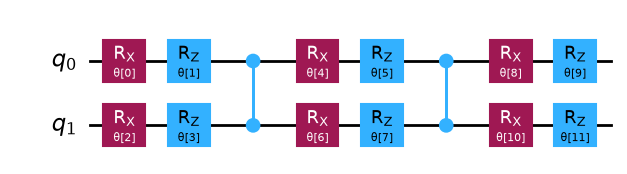

In [4]:
def make_ansatz(n_layers=1, n_qubits=2):
    theta = ParameterVector("θ", 2 * n_qubits * (n_layers + 1))
    qc = QuantumCircuit(n_qubits)
    k = 0
    for layer in range(n_layers + 1):
        if layer > 0:
            for q in range(n_qubits - 1):
                qc.cz(q, q + 1)
        for q in range(n_qubits):
            qc.rx(theta[k], q); qc.rz(theta[k + 1], q); k += 2
    return qc

make_ansatz(2).draw("mpl")

## 2. Measurement and uncertainty

`EnergyEvaluator` evaluates $E(\vec\theta)$ for a **batch** of parameter sets, with realistic shot noise. Each Pauli term $\langle P_i\rangle$ in $H=\sum_i c_i P_i$ is estimated from `shots` measurements with outcomes $\pm1$, so its standard error is $\sqrt{(1-\langle P_i\rangle^2)/N_\text{shots}}$. It returns energies with standard errors, and keeps count of the **cost** (parameter sets evaluated and shots used). With `shots=None` it returns exact values.

Shots are counted per Pauli term. On hardware, qubit-wise commuting terms can be measured together (as in Lecture 4), and `hamiltonian(R).group_commuting(qubit_wise=True)` finds these groups. Think about how to account for this fairly.

In [5]:
class EnergyEvaluator:
    def __init__(self, ansatz, hamiltonian, shots=SHOTS, seed=SEED):
        self.ansatz, self.shots = ansatz, shots
        self.rng = np.random.default_rng(seed)
        self.terms = [SparsePauliOp(p) for p in hamiltonian.paulis]
        self.coeffs = hamiltonian.coeffs.real
        self.is_identity = np.array([set(p.to_label()) == {"I"} for p in hamiltonian.paulis])
        self.estimator = StatevectorEstimator()
        self.n_evaluations = 0
        self.n_shots = 0

    def __call__(self, thetas):
        # Energies and standard errors for parameter sets of shape (N, n_params).
        thetas = np.atleast_2d(thetas)
        exact = self.estimator.run([(self.ansatz, [[t] for t in self.terms], thetas)]).result()[0].data.evs
        if self.shots is None:
            means, errs = exact, np.zeros_like(exact)
        else:
            errs = np.sqrt(np.clip(1 - exact**2, 0, None) / self.shots)
            means = exact + errs * self.rng.normal(size=exact.shape)
            means[self.is_identity], errs[self.is_identity] = 1.0, 0.0
        self.n_evaluations += len(thetas)
        self.n_shots += len(thetas) * int((~self.is_identity).sum()) * (self.shots or 0)
        return self.coeffs @ means, np.sqrt((self.coeffs[:, None]**2 * errs**2).sum(axis=0))

ansatz = make_ansatz(n_layers=1)
R = R_values[len(R_values) // 2]
energy = EnergyEvaluator(ansatz, hamiltonian(R))
theta_test = rng.uniform(0, 2 * np.pi, ansatz.num_parameters)
E, dE = energy(theta_test)
print(f"R = {R} pm: E = {E[0]:.4f} ± {dE[0]:.4f} Hartree (exact ground state {exact_ground_energy(R):.4f})")
print(f"cost so far: {energy.n_evaluations} evaluations, {energy.n_shots} shots")

R = 150.0 pm: E = -2.0145 ± 0.0080 Hartree (exact ground state -2.8247)
cost so far: 1 evaluations, 65536 shots


## 3. Optimisation and gradients

### Gradient methods (to implement)

Implement the three gradient methods from [Lecture 5](../../content/lectures/lecture5.md). Each takes a function `f` and parameters `theta` (shape `(P,)`), and returns an estimate of $\nabla f$. `f` accepts a whole **batch** of parameter sets, with shape `(N, P)`, and returns `N` values. Evaluate everything you need in a single call to `f`, which is much faster.

`check_gradient` compares your implementation with a high-accuracy reference using exact (noiseless) values, and prints the relative error. Finite difference (with a small step) and parameter shift should agree to many digits. SPSA is random, so its check averages many estimates. The error of the average only falls as $1/\sqrt{n}$, so a relative error of order $10^{-1}$ to $10^{-2}$ is expected.

In [6]:
def finite_difference_gradient(f, theta, c=0.1):
    """Central finite-difference estimate of the gradient of f at theta."""
    raise NotImplementedError("TODO")

def spsa_gradient(f, theta, c=0.1, rng=rng):
    """SPSA estimate of the gradient of f at theta, using only two evaluations of f."""
    raise NotImplementedError("TODO")

def parameter_shift_gradient(f, theta):
    """Parameter-shift gradient of f at theta. Exact when f is an expectation value of a circuit
    whose parameters each appear once, in a Pauli rotation gate."""
    raise NotImplementedError("TODO")


def check_gradient(gradient_fn, f_exact, theta, n_average=1, **kwargs):
    """Compare gradient_fn(f_exact, theta) (averaged over n_average estimates) with a reference."""
    try:
        g = np.mean([gradient_fn(f_exact, theta, **kwargs) for _ in range(n_average)], axis=0)
    except NotImplementedError:
        print(f"{gradient_fn.__name__}: not implemented yet")
        return
    eps, P = 1e-5, len(theta)
    vals = f_exact(theta + np.vstack([eps * np.eye(P), -eps * np.eye(P)]))
    reference = (vals[:P] - vals[P:]) / (2 * eps)
    rel = np.max(np.abs(g - reference)) / np.max(np.abs(reference))
    print(f"{gradient_fn.__name__}: relative error = {rel:.1e}" + (f" (average of {n_average})" if n_average > 1 else ""))

In [7]:
exact_energy = EnergyEvaluator(ansatz, hamiltonian(R), shots=None)
f_exact = lambda thetas: exact_energy(thetas)[0]

check_gradient(finite_difference_gradient, f_exact, theta_test, c=1e-3)
check_gradient(spsa_gradient, f_exact, theta_test, n_average=2000, c=1e-3)
check_gradient(parameter_shift_gradient, f_exact, theta_test)

finite_difference_gradient: not implemented yet
spsa_gradient: not implemented yet
parameter_shift_gradient: not implemented yet


### Optimisation

`gradient_descent` works with any of your gradient functions. For example, once your gradients work:

```python
energy = EnergyEvaluator(ansatz, hamiltonian(R))                 # with shot noise
f = lambda thetas: energy(thetas)[0]
theta, history = gradient_descent(f, theta_test, parameter_shift_gradient, eta=0.5, iterations=50,
                                  cost=lambda: energy.n_shots)
```

`history["cost"]` then lets you plot the energy against the number of shots used.

In [8]:
def gradient_descent(f, theta0, gradient_fn, eta=0.1, iterations=50, cost=None, **grad_kwargs):
    """Plain gradient descent on f. Records f (one extra evaluation per step), the parameters,
    and the cost so far, if `cost` is a function returning it."""
    theta = np.array(theta0, dtype=float)
    history = {"f": [], "theta": [], "cost": []}
    for _ in range(iterations):
        history["f"].append(f(theta[None])[0])
        history["theta"].append(theta.copy())
        history["cost"].append(cost() if cost else np.nan)
        theta = theta - eta * gradient_fn(f, theta, **grad_kwargs)
    return theta, {k: np.array(v) for k, v in history.items()}

## 4. Noise

`NoisyEnergyEvaluator` measures the energy as you would on real hardware. $H$ is split into groups of qubit-wise commuting terms, and each group is measured with its own basis-change circuit, transpiled for and run on a (fake) backend with realistic noise. It is much slower than `EnergyEvaluator`, so use it to *evaluate* optimised circuits rather than to optimise. To run on real hardware (bonus), pass a real backend instead.

In [9]:
class NoisyEnergyEvaluator:
    def __init__(self, ansatz, hamiltonian, backend, shots=SHOTS, seed=SEED):
        self.shots = shots
        self.groups = hamiltonian.group_commuting(qubit_wise=True)
        pm = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=seed)
        circuits = []
        for group in self.groups:
            qc = ansatz.copy()
            for q in range(qc.num_qubits):
                basis = {str(p[q]) for p in group.paulis} - {"I"}     # at most one letter per qubit
                if basis == {"X"}:
                    qc.h(q)
                elif basis == {"Y"}:
                    qc.sdg(q); qc.h(q)
            qc.measure_all()
            circuits.append(pm.run(qc))
        self.circuits = circuits
        self.sampler = Sampler(mode=backend)
        if backend.name.startswith("fake"):
            self.sampler.options.simulator.seed_simulator = seed

    def __call__(self, thetas):
        thetas = np.atleast_2d(thetas)
        results = self.sampler.run([(c, thetas) for c in self.circuits], shots=self.shots).result()
        E, var = np.zeros(len(thetas)), np.zeros(len(thetas))
        for group, res in zip(self.groups, results):
            masks = [(p.z | p.x) for p in group.paulis]               # qubits each term acts on
            for i in range(len(thetas)):
                counts = res.data.meas.get_counts(loc=i)
                bits = np.array([[int(b) for b in s[::-1]] for s in counts])   # bits[:, q] = qubit q
                n = np.array(list(counts.values()))
                # value of this group's part of H for each measured bit string
                vals = sum(c.real * (-1.0) ** (bits[:, m].sum(axis=1)) for c, m in zip(group.coeffs, masks))
                mean = (n * vals).sum() / n.sum()
                E[i] += mean
                var[i] += (n * (vals - mean) ** 2).sum() / n.sum() / n.sum()
        return E, np.sqrt(var)

noisy_energy = NoisyEnergyEvaluator(ansatz, hamiltonian(R), FakeFez())
E_noisy, dE_noisy = noisy_energy(theta_test)
E_ideal = exact_energy(theta_test)[0]
print(f"{len(noisy_energy.groups)} measurement settings")
print(f"E(theta_test): noisy {E_noisy[0]:.4f} ± {dE_noisy[0]:.4f},  noiseless {E_ideal[0]:.4f}")

4 measurement settings
E(theta_test): noisy -2.0124 ± 0.0068,  noiseless -2.0174


## Saving results

Save results as you go, so you never have to re-run long calculations just to change a plot.

In [10]:
def save_results(name, **arrays):
    """Save numpy arrays to results/<name>.npz, with the group settings in results/<name>.json."""
    out = Path("results"); out.mkdir(exist_ok=True)
    np.savez(out / f"{name}.npz", **arrays)
    (out / f"{name}.json").write_text(json.dumps({**SETTINGS, "time": time.ctime()}, indent=2, default=str))